# 项目：用线性回归预测房价数据

## 分析目标

此数据分析报告的目的是，基于已有的房屋销售价格，以及有关该房屋的属性，进行线性回归分析，从而利用得到的线性回归模型，能对以下未知售价的房屋根据属性进行价格预测：

面积为6500平方英尺，有4个卧室、2个厕所，总共2层，不位于主路，无客人房，带地下室，有热水器，没有空调，车位数为2，位于城市首选社区，简装修。

## 简介

数据集`house_price.csv`记录了超过五百栋房屋的交易价格，以及房屋的相关属性信息，包括房屋面积、卧室数、厕所数、楼层数、是否位于主路、是否有客房，等等。

`house_price.csv`每列的含义如下：
- price：房屋出售价格
- area：房屋面积，以平方英尺为单位
- bedrooms：卧室数
- bathrooms：厕所数
- stories：楼层数
- mainroad：是否位于主路
   - yes  是
   - no	  否
- guestroom：是否有客房
   - yes  是
   - no	  否
- basement：是否有地下室
   - yes  是
   - no	  否
- hotwaterheating：是否有热水器
   - yes  是
   - no	  否
- airconditioning：是否有空调
   - yes  是
   - no	  否
- parking：车库容量，以车辆数量为单位
- prefarea：是否位于城市首选社区
   - yes  是
   - no	  否
- furnishingstatus：装修状态
   - furnished       精装
   - semi-furnished	 简装
   - unfurnished     毛坯

In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [43]:
house_price = pd.read_csv(r'C:\Users\30338\Desktop\数据处理学习\5数据分析\house_price.csv')
house_price.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [44]:
c_hp=house_price.copy()
c_hp.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


### 数据清洗  
对数据结构和内容上的问题进行清洗。结构上：整洁数据包含三个特点:1.每列是一个变量 2.每行是一个观察值 3.每个单元格是一个值。  
内容上：脏数据包括：丢失、重复、无效错误(脱离实际)、不一致数据(单位\全称\简写不一致等)。  

##### 经观察发现并不存在结构性问题，因此不对数据进行结构清洗，接下来进行脏数据的清洗和查看

#### 数据丢失

In [45]:
c_hp.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


##### 从上可见，并不存在数据丢失的情况、数据也都符合其相应字符类型，但是furnishingstatus被分为三类，包括mainroad、guestroom、basement、hotwaterheating、aircondition、prefarea等也被分为两类，接下来查看其是否存在不一致数据

In [46]:
print(c_hp["furnishingstatus"].value_counts())
print(c_hp["mainroad"].value_counts())
print(c_hp["guestroom"].value_counts())
print(c_hp["basement"].value_counts())
print(c_hp["hotwaterheating"].value_counts())
print(c_hp["airconditioning"].value_counts())
print(c_hp["prefarea"].value_counts())

furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64
mainroad
yes    468
no      77
Name: count, dtype: int64
guestroom
no     448
yes     97
Name: count, dtype: int64
basement
no     354
yes    191
Name: count, dtype: int64
hotwaterheating
no     520
yes     25
Name: count, dtype: int64
airconditioning
no     373
yes    172
Name: count, dtype: int64
prefarea
no     417
yes    128
Name: count, dtype: int64


##### 经过观察发现数据并不存在不一致，因此不对其进行其他处理；  
由于变量含义的特殊性，因此允许存在重复数据，不对其进行专门处理；  
接下来观察是否存在失效或错误数据

In [47]:
c_hp.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


##### 经过观察发现并不存在不合理数据，因此不进行处理，可以考虑将furnishingstatus的数据类型转换成category从而缩减存储空间。

In [48]:
c_hp["furnishingstatus"].astype("category")

0           furnished
1           furnished
2      semi-furnished
3           furnished
4           furnished
            ...      
540       unfurnished
541    semi-furnished
542       unfurnished
543         furnished
544       unfurnished
Name: furnishingstatus, Length: 545, dtype: category
Categories (3, str): ['furnished', 'semi-furnished', 'unfurnished']

## 数据探索

##### 在着手推断统计学分析之前，可先借助数据可视化，探索数值变量的分布，及与房价存在相关性的变量，为后续的进一步分析提供方向。

##### 设置调色盘pastel

In [49]:
sns.set_palette("pastel")

#### 1.房价分布

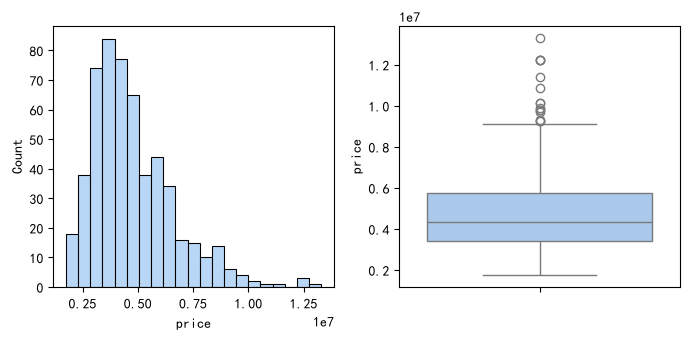

In [50]:
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号  
plt.rcParams['figure.figsize'] = (7.00, 3.50)  # 设置图形大小
plt.rcParams['figure.autolayout'] = True     
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x="price", ax=axes[0])
sns.boxplot(c_hp, y="price", ax=axes[1])
plt.show()

##### 通过观察可以发现，房价整体呈现右偏态，箱型图可以发现，有一些极端数据使得整体的平均水平被抬升

#### 2.面积分布

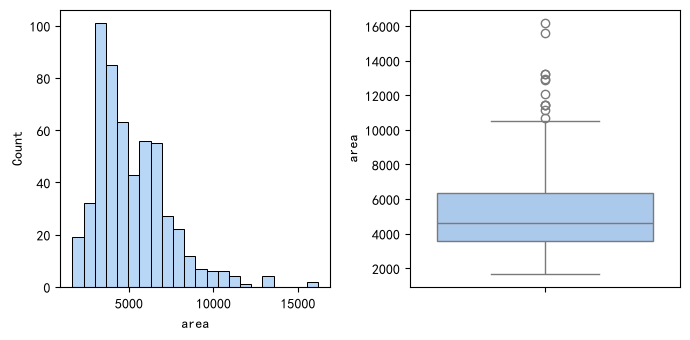

In [51]:
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x='area', ax=axes[0])
sns.boxplot(c_hp, y='area', ax=axes[1])
plt.show()

##### 面积和房价一样也呈现右偏态分布

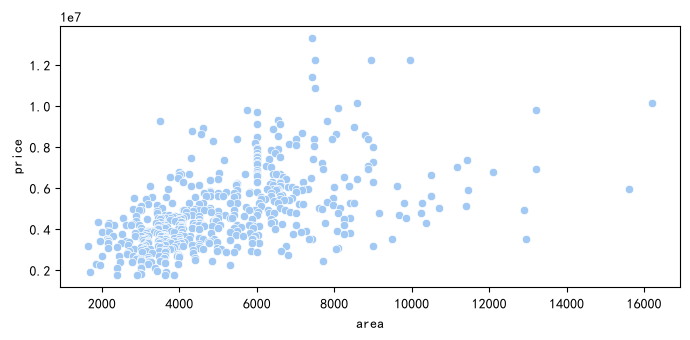

In [52]:
sns.scatterplot(c_hp, x='area', y='price')
plt.show()

##### 从图中能看出面积和房价存在一些正相关关系

#### 卧室数量和价格之间的关系

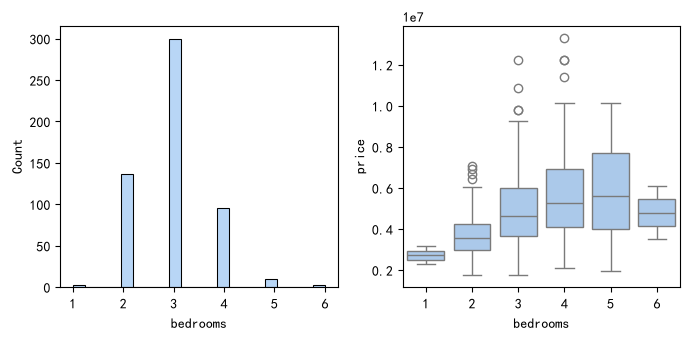

In [53]:
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x='bedrooms', ax=axes[0])
sns.boxplot(c_hp, x='bedrooms', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子的卧室数范围为1-6个，其中大多房子有2-4个。  
从平均房价与卧室数之间的柱状图来看，当卧室数小于5个时，卧室数多的房子价格也相应高，但一旦多于5个，房价并不一定相应更高。  
接下来是洗手间和房价的关系

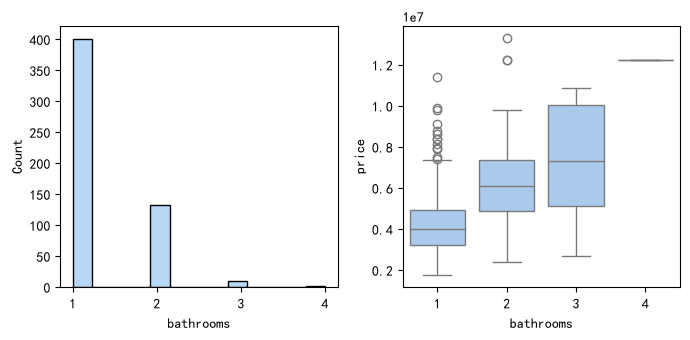

In [54]:
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x='bathrooms', ax=axes[0])
sns.boxplot(c_hp, x='bathrooms', y='price', ax=axes[1])
plt.show()

##### 数据集中房子洗手间数量最少1个，最多4个，其中为1个的数量最多。从平均房价与洗手间数之间的柱状图来看，洗手间多的房子价格也相应高.  
接下来是楼层数与房价的关系

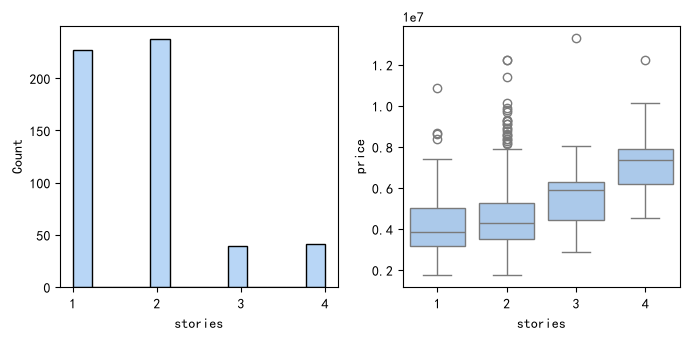

In [55]:
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x='stories', ax=axes[0])
sns.boxplot(c_hp, x='stories', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子的楼层数范围为1-4层，其中大多房子有1层或2层。从平均房价与楼层数之间的柱状图来看，楼层多的房子价格也相应高。  
接下来是车库数量与房价

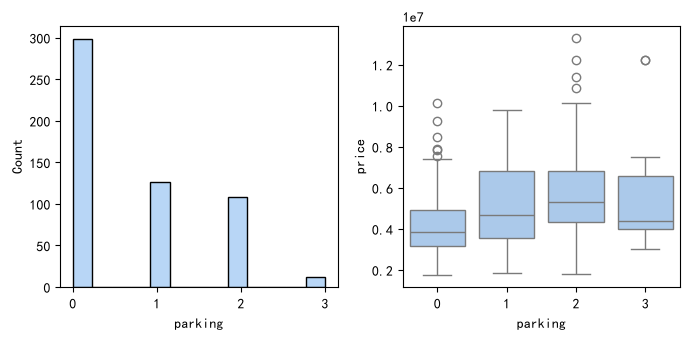

In [56]:
figure, axes = plt.subplots(1, 2)
sns.histplot(c_hp, x='parking', ax=axes[0])
sns.boxplot(c_hp, x='parking', y='price', ax=axes[1])
plt.show()

此数据集中房子的车库数范围为0-3个，不带车库的房子数量是最多的，其次是1个和2个。

从平均房价与楼层数之间的柱状图来看，车库多的房子价格也相应高，但超过2个后，房价并不一定相应更高。  
接下来是有或没有主路对房价的影响

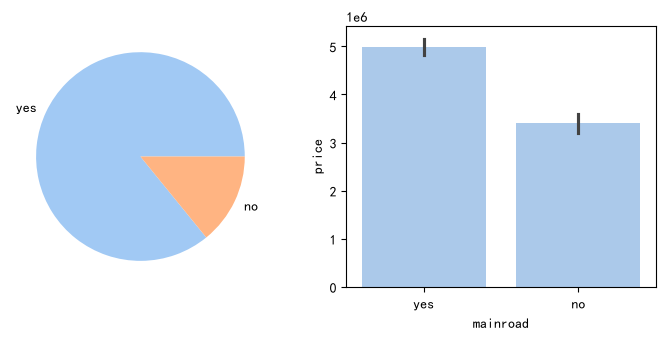

In [57]:
figure, axes = plt.subplots(1, 2)
mc=c_hp["mainroad"].value_counts()
ml=mc.index
axes[0].pie(mc, labels=ml)
sns.barplot(c_hp, x='mainroad', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大多数位于主路。从平均房价与楼层数之间的柱状图来看，在主路的的房子价格也相应高。  
接下来是是否有客人房和房价的关系

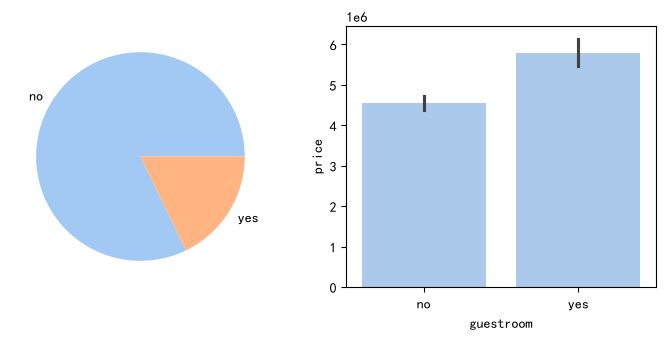

In [58]:
figure, axes = plt.subplots(1, 2)
gc=c_hp["guestroom"].value_counts()
gl=gc.index
axes[0].pie(gc, labels=gl)
sns.barplot(c_hp, x='guestroom', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大部分没有客人房。从平均房价与楼层数之间的柱状图来看，有客人房的的房子价格也相应高。  
接下来是是否有地下室与房价

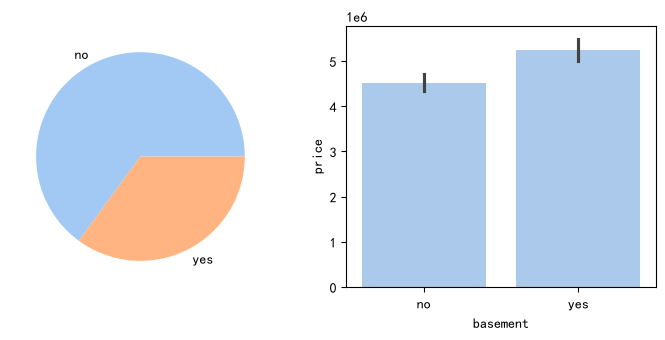

In [59]:
figure, axes = plt.subplots(1, 2)
bc=c_hp["basement"].value_counts()
bl=bc.index
axes[0].pie(bc, labels=bl)
sns.barplot(c_hp, x='basement', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大部分没有地下室。从平均房价与地下室之间的柱状图来看，有地下室的的房子价格也相应高。  
接下来是是否有热水器与房价

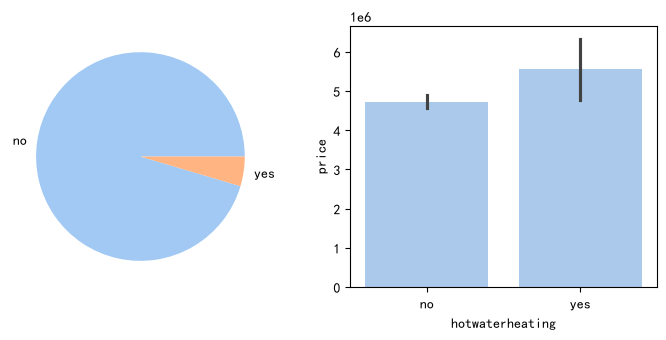

In [60]:
figure, axes = plt.subplots(1, 2)
hc=c_hp["hotwaterheating"].value_counts()
hl=hc.index
axes[0].pie(hc, labels=hl)
sns.barplot(c_hp, x='hotwaterheating', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大部分没有热水器。从平均房价与热水器之间的柱状图来看，有热水器的的房子价格也相应高。  
接下来是是否有空调与房价

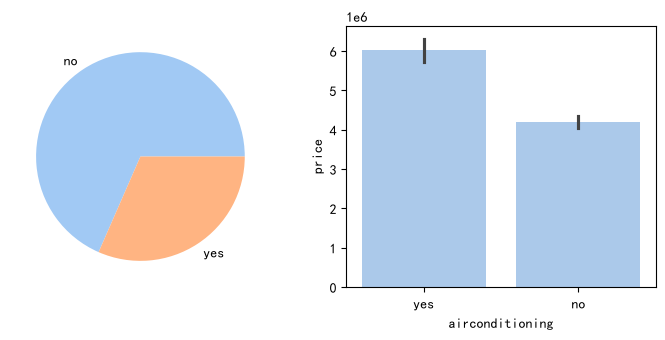

In [61]:
figure, axes = plt.subplots(1, 2)
ac=c_hp["airconditioning"].value_counts()
al=ac.index
axes[0].pie(ac, labels=al)
sns.barplot(c_hp, x='airconditioning', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大部分没有空调。从平均房价与空调之间的柱状图来看，有空调的房子价格也相应高。  
接下来是是否处于城区首选社区与房价的关系

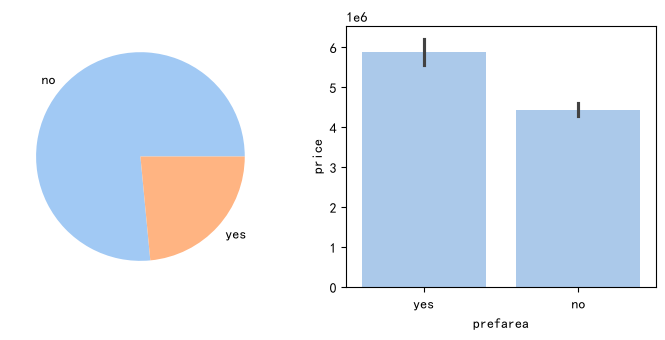

In [62]:
figure, axes = plt.subplots(1, 2)
pc=c_hp["prefarea"].value_counts()
pl=pc.index
axes[0].pie(pc, labels=pl)
sns.barplot(c_hp, x='prefarea', y='price', ax=axes[1])
plt.show()

##### 此数据集中房子大部分不处于城区首选社区。从平均房价与社区之间的柱状图来看，处于首选位置的房子价格也相应高。  
接下来看装修状态与房价的关系

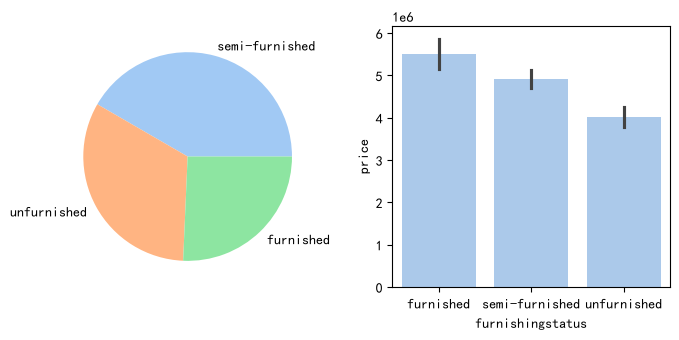

In [63]:
figure, axes = plt.subplots(1, 2)
fc=c_hp["furnishingstatus"].value_counts()
fl=fc.index
axes[0].pie(fc, labels=fl)
sns.barplot(c_hp, x='furnishingstatus', y='price', ax=axes[1])
plt.show()

此数据集中简装和毛坯的房子较多，1/4左右房子为精装。从平均房价与装修状态之间的柱状图来看，精装的房子价格高于简装，简装高于毛坯。

## 分析数据
在分析步骤中，我们将利用`cleaned_house_price`的数据，进行线性回归分析，目标是得到一个可以根据房屋各个属性对价格进行预测的数学模型。  先引入做线性回归所需的模块statsmodels.api。

In [64]:
c_hp

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [65]:
import statsmodels.api as sm

In [66]:
lr_hp=c_hp.copy()
lr_hp
#为了避免赋值的新变量会影响原来的数据，使用copy()方法创建一个新的数据副本来用于分析。

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [67]:
nlr_hp=pd.get_dummies(lr_hp, columns=['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus'], dtype=int,drop_first=True)
nlr_hp

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,2,1,0,1,0,0,0,0,1
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,1,0
542,1750000,3620,2,1,1,0,1,0,0,0,0,0,0,1
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,0,0


In [68]:
#接下来需要将因变量和自变量分开，因变量是房价price，自变量是其他所有的列，从而得出一个能根据其他可能对房屋价格产生影响的变量，从而预测销售价格模型。
#也就是分别提取：
Y=nlr_hp['price']

In [69]:
#接下来可以将因变量之外的所有值都纳入自变量，但需要查看它们之间的相关性，查看自变量之间是否存在多重共线性问题。
X=nlr_hp.drop('price', axis=1)

In [70]:
X.corr().abs()>0.8
#经过广播筛选，发现没有数据存在共线性问题，因此不需要从X中移除更多的变量的。

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
area,True,False,False,False,False,False,False,False,False,False,False,False,False
bedrooms,False,True,False,False,False,False,False,False,False,False,False,False,False
bathrooms,False,False,True,False,False,False,False,False,False,False,False,False,False
stories,False,False,False,True,False,False,False,False,False,False,False,False,False
parking,False,False,False,False,True,False,False,False,False,False,False,False,False
mainroad_yes,False,False,False,False,False,True,False,False,False,False,False,False,False
guestroom_yes,False,False,False,False,False,False,True,False,False,False,False,False,False
basement_yes,False,False,False,False,False,False,False,True,False,False,False,False,False
hotwaterheating_yes,False,False,False,False,False,False,False,False,True,False,False,False,False
airconditioning_yes,False,False,False,False,False,False,False,False,False,True,False,False,False


##### 接下来给模型的线性方程添加截距

In [71]:
X= sm.add_constant(X)
X

,const,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,1.0,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,1.0,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,1.0,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,1.0,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,1.0,7420,4,1,2,2,1,1,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1.0,3000,2,1,1,2,1,0,1,0,0,0,0,1
541,1.0,2400,3,1,1,0,0,0,0,0,0,0,1,0
542,1.0,3620,2,1,1,0,1,0,0,0,0,0,0,1
543,1.0,2910,3,1,1,0,0,0,0,0,0,0,0,0


In [72]:
#这一步就可以调用OLS函数，利用最小二乘法来得到线性回归模型的参数值,再加入fit方法来对数据进行拟合，如此一来model中就有线性回归模型的拟合结果了。
model=sm.OLS(Y,X).fit()

In [73]:
#查看所有计算出来的参数可以通过summary方法
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     87.52
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          9.07e-123
Time:                        22:09:07   Log-Likelihood:                -8331.5
No. Observations:                 545   AIC:                         1.669e+04
Df Residuals:                     531   BIC:                         1.675e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                            4.277e+04   2.64e+05      0.162      0.872   -4.76e+05    5.62e+05
area                              244.1394     24.289     10.052      0.000     196.425     291.853
bedrooms                         1.148e+05   7.26e+04      1.581      0.114   -2.78e+04    2.57e+05
bathrooms                        9.877e+05   1.03e+05      9.555      0.000    7.85e+05    1.19e+06
stories                          4.508e+05   6.42e+04      7.026      0.000    3.25e+05    5.77e+05
parking                          2.771e+05   5.85e+04      4.735      0.000    1.62e+05    3.92e+05
mainroad_yes                     4.213e+05   1.42e+05      2.962      0.003    1.42e+05    7.01e+05
guestroom_yes                    3.005e+05   1.32e+05      2.282      0.023    4.18e+04    5.59e+05
basement_yes                     3.501e+05    1.1e+05      3.175      0.002    1.33e+05    5.67e+05
hotwaterheating_yes              8.554e+05   2.23e+05      3.833      0.000    4.17e+05    1.29e+06
airconditioning_yes               8.65e+05   1.08e+05      7.983      0.000    6.52e+05    1.08e+06
prefarea_yes                     6.515e+05   1.16e+05      5.632      0.000    4.24e+05    8.79e+05
furnishingstatus_semi-furnished -4.634e+04   1.17e+05     -0.398      0.691   -2.75e+05    1.83e+05
furnishingstatus_unfurnished    -4.112e+05   1.26e+05     -3.258      0.001   -6.59e+05   -1.63e+05
==============================================================================
Omnibus:                       97.909   Durbin-Watson:                   1.209
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              258.281
Skew:                           0.895   Prob(JB):                     8.22e-57
Kurtosis:                       5.859   Cond. No.                     3.49e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.49e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [74]:
#当显著区间设定为0.05时，通过p值对比可以发现，模型认为以下因素对于房屋价格没有显著性影响：const、bedrooms、furnishingstatus_semi-furnished
#此时可以将这些变量移除，再次建立线性回归模型。
X=X.drop(["const","bedrooms","furnishingstatus_semi-furnished"],axis=1)


In [75]:
#此时就可以再次调用OLS
model=sm.OLS(Y,X).fit()


In [76]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  price   R-squared (uncentered):                   0.957
Model:                            OLS   Adj. R-squared (uncentered):              0.956
Method:                 Least Squares   F-statistic:                              1088.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):                        0.00
Time:                        22:09:07   Log-Likelihood:                         -8333.5
No. Observations:                 545   AIC:                                  1.669e+04
Df Residuals:                     534   BIC:                                  1.674e+04
Df Model:                          11                                                  
Covariance Type:            nonrobust                                                  
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
area                           257.5854     22.577     11.409      0.000     213.234     301.936
bathrooms                     1.071e+06   9.27e+04     11.553      0.000    8.89e+05    1.25e+06
stories                       5.084e+05   5.71e+04      8.898      0.000    3.96e+05    6.21e+05
parking                       2.793e+05   5.83e+04      4.794      0.000    1.65e+05    3.94e+05
mainroad_yes                  4.672e+05   1.27e+05      3.679      0.000    2.18e+05    7.17e+05
guestroom_yes                 2.851e+05   1.31e+05      2.172      0.030    2.72e+04    5.43e+05
basement_yes                  4.016e+05   1.07e+05      3.765      0.000    1.92e+05    6.11e+05
hotwaterheating_yes           8.668e+05   2.23e+05      3.884      0.000    4.28e+05    1.31e+06
airconditioning_yes           8.543e+05   1.07e+05      7.952      0.000    6.43e+05    1.07e+06
prefarea_yes                  6.443e+05   1.15e+05      5.594      0.000    4.18e+05    8.71e+05
furnishingstatus_unfurnished -3.493e+05   9.49e+04     -3.679      0.000   -5.36e+05   -1.63e+05
==============================================================================
Omnibus:                       94.840   Durbin-Watson:                   1.262
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              251.889
Skew:                           0.865   Prob(JB):                     2.01e-55
Kurtosis:                       5.845   Cond. No.                     2.74e+04
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 2.74e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

##### 可以观察到，经过不相关变量的移除操作后，R值由0.682增大至0.957，模型拟合度得到提升  
coef中只有furnishingstatus_unfurnished为负数，表示只有furnishingstatus_unfurnished的值会对房屋价格有负面影响。

#所需要预测房价的房屋面积信息为：
#:6500平方英尺，有4个卧室、2个厕所，总共2层，不位于主路，无客人房，带地下室，有热水器，没有空调，车位数为2，位于城市首选社区，简装修。


In [77]:
#新建字典DF来放入房屋信息，键对应列名，值是每行数据；需要加新的房屋信息，就直接在值里添加信息即可。
price_to_predict=pd.DataFrame({'area':[6500],"bedrooms":[4],"bathrooms":[2],"stories":[2],"mainroad":["no"],"guestroom":["no"],"basement":["yes"],"hotwaterheating":["yes"],"airconditioning":["no"],"parking":[2],"prefarea":["yes"],"furnishingstatus":["semi-furnished"]})
price_to_predict

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,6500,4,2,2,no,no,yes,yes,no,2,yes,semi-furnished


In [78]:
price_to_predict["mainroad"]=pd.Categorical(price_to_predict["mainroad"],categories=['no','yes'])
price_to_predict["guestroom"]=pd.Categorical(price_to_predict["guestroom"],categories=['no','yes'])
price_to_predict["basement"]=pd.Categorical(price_to_predict["basement"],categories=['no','yes'])
price_to_predict["hotwaterheating"]=pd.Categorical(price_to_predict["hotwaterheating"],categories=['no','yes'])
price_to_predict["airconditioning"]=pd.Categorical(price_to_predict["airconditioning"],categories=['no','yes'])
price_to_predict["prefarea"]=pd.Categorical(price_to_predict["prefarea"],categories=['no','yes'])
price_to_predict["furnishingstatus"]=pd.Categorical(price_to_predict["furnishingstatus"],categories=['furnished','semi-furnished','unfurnished'])

In [79]:
#接下来引入虚拟变量
price_to_predict=pd.get_dummies(price_to_predict, columns=['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus'], dtype=int,drop_first=True)
price_to_predict.head()
#由于第二次运行get_dummies时，列表里的数据已经被删除了，所以找不到，就会报错，此时可以将前面的再运行一次。

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,6500,4,2,2,2,0,0,1,1,0,1,1,0


In [80]:
#经过观察可以发现，分类变量已经经过get_dummies成功转化为虚拟变量,此时还不可以直接去预测：还需要将模型未用到的自变量从中删除
#也就是需要保证预测数据的变量和模型输入的变量一致，先看X里还有什么
X

,area,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_unfurnished
0,7420,2,3,2,1,0,0,0,1,1,0
1,8960,4,4,3,1,0,0,0,1,0,0
2,9960,2,2,2,1,0,1,0,0,1,0
3,7500,2,2,3,1,0,1,0,1,1,0
4,7420,1,2,2,1,1,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
540,3000,1,1,2,1,0,1,0,0,0,1
541,2400,1,1,0,0,0,0,0,0,0,0
542,3620,1,1,0,1,0,0,0,0,0,1
543,2910,1,1,0,0,0,0,0,0,0,0


In [81]:
#经过观察发现没有bedrooms列、furnishingstatus_semi-furnished列
price_to_predict=price_to_predict.drop(['bedrooms','furnishingstatus_semi-furnished'],axis=1)
#constant不作删除是因为接下来可以不加入截距就行。

In [82]:
#接下来调用线性回归模型的predict方法来获取预测价格。
price_value=model.predict(price_to_predict)
price_value

0    7.303754e+06
dtype: float64

### 线性回归模型预测的房屋价格为：7071927